# Supervised Learning Questions — the Internals Round

These are the questions where "I've used sklearn" stops being enough: *why* is logistic regression called regression, what exactly does the SVM kernel trick buy, when does Naive Bayes beat a neural net. Each answer is paired with an executed demo so the intuition you quote is one you've watched happen.

## Q1 — Linear Regression: Assumptions, in the Order They're Actually Violated

The textbook lists five; interviewers probe whether you know which ones *matter* and *when*:

1. **Linearity** of the relation between features and target (in the *coefficients*, not the features — you can model x² by adding it as a feature). Violation → biased estimates, fix with transforms/interactions.
2. **Independence of errors** — autocorrelation (time series, repeated users) wrecks standard errors. Fix: cluster-robust SEs, time-series models.
3. **Homoscedasticity** — constant error variance. Heteroscedasticity → SEs wrong (predictions still unbiased). Fix: log-transform the target, weighted least squares.
4. **Normality of errors** — needed only for exact small-sample CIs/p-values; irrelevant for prediction. The assumption people over-worry about.
5. **No (near-)multicollinearity** — correlated features make individual coefficients unstable while *predictions* can stay fine. Diagnose with VIF; fix by dropping/combining or ridge.

**The framing that scores:** *"assumptions 1–2 bias the model, 3–5 corrupt the inference — for pure prediction I care mostly about 1; for explaining coefficients I care about all five."*

In [1]:
import numpy as np
import statsmodels.api as sm

rng = np.random.default_rng(0)
n = 300
x = rng.uniform(0, 10, n)
# heteroscedastic noise: variance grows with x
y = 2 + 1.5 * x + rng.normal(0, 0.3 * x, n)

fit = sm.OLS(y, sm.add_constant(x)).fit()
print("coefficient on x:", fit.params[1].round(3), "(true 1.5)")
print("R-squared        :", round(fit.rsquared, 3))
resid_std = [float(np.std(y[abs(x - v) < 1] - (fit.params[0] + fit.params[1] * v))) for v in (2, 5, 8)]
print("residual spread at x=2/5/8:", [round(s, 2) for s in resid_std], " <- grows: heteroscedasticity")

coefficient on x: 1.483 (true 1.5)
R-squared        : 0.865
residual spread at x=2/5/8: [1.06, 1.67, 2.39]  <- grows: heteroscedasticity


## Q2 — Why Is Logistic Regression Called Regression?

Because it *is* a regression — a linear model predicting a conditional expectation — whose target happens to be P(y=1|x) ∈ [0,1], squashed through the sigmoid link. It's classification only because we threshold the probability. Bonus precision: logistic regression is a **GLM** (generalized linear model) with the Bernoulli family and logit link; linear regression is the Gaussian family with identity link. And the decision boundary is linear: σ(w·x)=0.5 ⟺ w·x=0.

## Q3 — Logistic Loss vs MSE: Why Cross-Entropy?

Two reasons, and say both: (1) **probabilistic correctness** — cross-entropy is the negative log-likelihood of the Bernoulli model, so optimizing it *is* maximum likelihood; (2) **optimization** — combined with the sigmoid, its gradient is simply `ŷ − y` (clean, non-vanishing), while MSE-on-sigmoid is non-convex with plateaus where the sigmoid saturates. That clean gradient is also why the DL notebook's from-scratch nets train so easily.

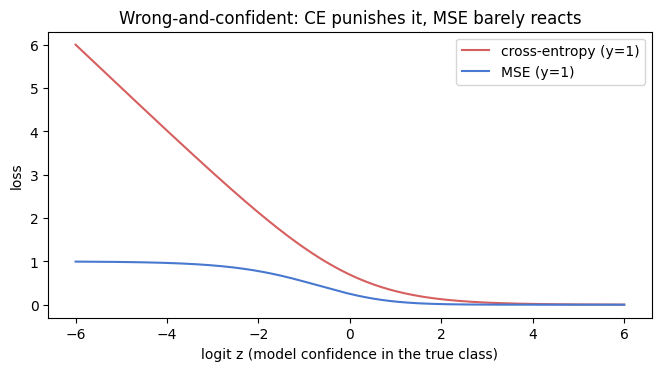

In [2]:
import matplotlib.pyplot as plt

z = np.linspace(-6, 6, 400)
p = 1 / (1 + np.exp(-z))

ce  = -np.log(np.clip(p, 1e-9, 1))            # loss for the true class
mse = (p - 1) ** 2                             # squared error vs. target 1

plt.figure(figsize=(6.5, 3.6), constrained_layout=True)
plt.plot(z, ce, label="cross-entropy (y=1)", color="#D65F5F")
plt.plot(z, mse, label="MSE (y=1)", color="#4878CF")
plt.xlabel("logit z (model confidence in the true class)")
plt.ylabel("loss"); plt.legend()
plt.title("Wrong-and-confident: CE punishes it, MSE barely reacts")
plt.show()

## Q4 — SVM: Margins, Hinge Loss, and the Kernel Trick

**The 60-second core:** SVM finds the hyperplane maximizing the *margin* between classes. Only points on the margin (support vectors) matter; everything else could vanish. Soft margin (C) tolerates violations — C is the regularization knob: **large C = hard margin = low bias/high variance; small C = more tolerance, wider margin.**

**The kernel trick, said properly:** the dual optimization depends only on **inner products** ⟨xᵢ, xⱼ⟩. Replace them with k(xᵢ, xⱼ) = ⟨φ(xᵢ), φ(xⱼ)⟩ and you're training in a high-dimensional feature space **without ever computing φ(x)** — the kernel computes the inner product directly (for RBF: exp(−γ‖xᵢ−xⱼ‖²)). Non-linear boundaries at the cost of one function evaluation per pair.

In [3]:
from sklearn.svm import SVC
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=300, noise=0.18, random_state=3)

lin = SVC(kernel="linear", C=1.0).fit(X, y)
rbf = SVC(kernel="rbf", gamma="scale", C=1.0).fit(X, y)
print(f"linear SVM accuracy: {lin.score(X, y):.3f}")
print(f"RBF    SVM accuracy: {rbf.score(X, y):.3f}   <- kernel makes linear machinery non-linear")
print(f"support vectors: linear {lin.support_.size}, rbf {rbf.support_.size} of {len(X)} points")

linear SVM accuracy: 0.853
RBF    SVM accuracy: 0.950   <- kernel makes linear machinery non-linear
support vectors: linear 107, rbf 73 of 300 points


**Follow-up chain:** *γ?* RBF reach — large γ → wiggly boundary (overfit), small γ → nearly linear. *When not SVM?* Big n (kernel matrix is n², doesn't scale past ~10⁵ rows); probability outputs needed (needs Platt scaling). *Hinge loss form?* max(0, 1 − y·f(x)) — margin-punishing, linear-growth — different flavor from log loss's exponential growth; that's why SVM isn't calibrated.

## Q5 — KNN: Everything Reducible to Three Choices

*k* (bias-variance dial — small k overfits), *distance metric* (Euclidean/Manhattan/cosine — must match the geometry of the feature space), and *weighting* (uniform vs distance-weighted votes). Everything else is engineering: KD-trees for speed, scaling for fairness across features. And the two big caveats to volunteer: **curse of dimensionality** (distances concentrate in high-d; margins between nearest and farthest shrink) and **lazy learning** (no training, all cost at inference — the opposite of most models).

In [4]:
# the curse, demonstrated: distance contrast dies as dimensionality grows
rng = np.random.default_rng(0)
for d in (2, 10, 100, 1000):
    X = rng.random((500, d))
    dists = np.sqrt(((X[:, None] - X[None, :]) ** 2).sum(-1) + np.eye(500))
    nearest = dists.min(axis=1)
    farthest = dists.max(axis=1)
    print(f"d={d:>5}: nearest/farthest ratio = {(nearest/farthest).mean():.3f}  -> 1.0 means nearest ~= farthest: no signal")

d=    2: nearest/farthest ratio = 0.021  -> 1.0 means nearest ~= farthest: no signal
d=   10: nearest/farthest ratio = 0.296  -> 1.0 means nearest ~= farthest: no signal
d=  100: nearest/farthest ratio = 0.212  -> 1.0 means nearest ~= farthest: no signal


d= 1000: nearest/farthest ratio = 0.074  -> 1.0 means nearest ~= farthest: no signal


## Q6 — Naive Bayes: Why 'Naive' and Why It Still Wins Sometimes

**Naive** = conditional independence of features given the class — almost never true, yet the classifier is often fine, because NB only needs the *argmax* over classes to be right, not the probability estimates (and misestimated posteriors frequently preserve the ordering). Strengths: trains in one pass, scales infinitely, natural multi-class, superb with high-dimensional sparse data (spam, text) where logistic regression needs regularization to match it. Weaknesses: probability calibration is poor (say this: *over-confident because errors from the independence assumption accumulate*), correlated features double-count evidence — the m-estimate/Laplace smoothing detail: α=1 pseudo-counts stop zero-probability wipeouts for unseen words.

In [5]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer

texts = ["free money now click here", "meeting scheduled tomorrow team",
         "win a free iphone click", "quarterly report attached review",
         "claim your prize free", "project deadline moved friday"] * 8
labels = [1, 0, 1, 0, 1, 0] * 8      # 1 = spam

vec = CountVectorizer()
nb = MultinomialNB(alpha=1.0).fit(vec.fit_transform(texts), labels)

test = vec.transform(["free prize click now", "team meeting tomorrow review"])
probs = nb.predict_proba(test)
print("P(spam) 'free prize click now'          :", f"{probs[0,1]:.3f}")
print("P(spam) 'team meeting tomorrow review'  :", f"{probs[1,1]:.3f}")
print("note: probabilities are sharp, not calibrated — NB ranks well, estimates poorly")

P(spam) 'free prize click now'          : 1.000
P(spam) 'team meeting tomorrow review'  : 0.000
note: probabilities are sharp, not calibrated — NB ranks well, estimates poorly


## Q7 — Imbalanced Classification: The Full Answer

The question is always "accuracy is 99% on fraud, is the model good?" — No, if the base rate is 99.3%. The layered answer:

1. **Measure right:** ROC-AUC misleads under heavy imbalance; use PR-AUC, recall@precision, or cost-weighted metrics (the [Metrics notebook](Model%20Evaluation%20Questions.ipynb) demos the divergence).
2. **Resample inside the pipeline:** oversample minority (SMOTE synthesizes interpolated minority points — inside CV folds only), undersample majority, or both. Never resample the validation set.
3. **Reweight:** `class_weight='balanced'` / loss weights — same effect as oversampling without duplicate rows.
4. **Threshold-move, don't resample:** often the cheapest fix — pick the operating point from the precision-recall curve against the business cost (false positive vs false negative cost).
5. **Frame honestly:** sometimes the right answer is ranking + human review capacity, not automated classification.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=4000, weights=[0.97], n_informative=4,
                           flip_y=0.02, random_state=0)   # 3% positive class
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

plain = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
bal   = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr, ytr)

for name, m in [("plain", plain), ("balanced", bal)]:
    p = m.predict_proba(Xte)[:, 1]
    print(f"{name:>9}: accuracy {(m.predict(Xte)==yte).mean():.3f} | "
          f"ROC-AUC {roc_auc_score(yte, p):.3f} | PR-AUC {average_precision_score(yte, p):.3f}")
print("balanced model 'loses' accuracy, wins recall — which one is right depends on costs, not averages")

    plain: accuracy 0.968 | ROC-AUC 0.671 | PR-AUC 0.394
 balanced: accuracy 0.657 | ROC-AUC 0.722 | PR-AUC 0.221
balanced model 'loses' accuracy, wins recall — which one is right depends on costs, not averages


## Q8 — Quick-Fire Supervised Round

| Question | The 15-second answer |
| --- | --- |
| Linear regression confidence interval vs prediction interval? | CI: uncertainty about the *mean* line; PI: uncertainty about a *single point* — PI ⊃ CI, always wider |
| ElasticNet? | α·L1 + (1−α)·L2 blend; inherits sparsity and stability; α tuned when you want selection but have correlated features |
| Can linear regression handle categorical targets? | No — that's what logistic (binary) / multinomial (multi-class) / ordinal regression are for; say the GLM framing |
| OVR vs multinomial (softmax)? | One-vs-rest trains K binary models (calibration drift, correlated errors); softmax trains one joint model — usually better, what sklearn does now by default |
| Kernel trick computational cost? | Kernel matrix n² storage/n³ solve — SVMs stop scaling ~10⁴-10⁵ rows; linear kernels (SGD, LibLinear) or gradient boosting for bigger |
| When does KNN beat trees? | Smooth local structure, low dimensions, irregular boundaries, small data; trees win on tabular heterogenous features at scale |
| Laplace smoothing? | P(word|class) = (count+α)/(total+α·V) — α pseudo-counts prevent zero probabilities wiping out the whole product; α=1 default |
| Precision/Recall tradeoff origin? | One threshold slides both in opposite directions; AUC summarizes all thresholds — the Metrics notebook shows the curve |